# Notebook 01 - Data preprocessing
**AI-100 Lab 2

The data in the real world is DIRTY

**Your job:** find what is missing, paste in the fixes ("patches"), and exaime the **Scoreboard** at the bottom improve.

| Goal | Baseline (no patches) | All 9 patches |
|---|---|---|
| Linear regression R² (higher is better) | ≈ 0.75 | ≈ 0.87 |
| Linear regression MAE in points (lower is better) | ≈ 6.3 | ≈ 4.5 |
| Logistic regression AUC (higher is better) | ≈ 0.91 | ≈ 0.97 |

### How to work through this notebook
1. **First, run everything as it is:** *Kernel → Restart Kernel and Run All Cells* (Colab: *Runtime → Restart and run all*). Scroll to the Scoreboard: that is your **baseline**.
2. Go top to bottom. At each **Patch** box:
   - read the **Symptom** (what is wrong and where you can see it),
   - write your **prediction** (up / down / same),
   - **copy** the code and **paste** it into the empty cell right below the box (the one that starts with `# PATCH n`),
   - **Restart & Run All** again. Always restart: some patches (like Patch 6) change columns and cannot run twice.
3. The Scoreboard **remembers every run**, so you can see what each patch did. Was your prediction right?
4. Answer each **Checkpoint** by replacing `?` in `check("P1", "?")` with your answer and running the cell.

> The data is **synthetic**. No real student is in it.

## Step 0 - Setup

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score, mean_absolute_error, accuracy_score, roc_auc_score
import joblib

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "make_data.py").exists())
sys.path.append(str(ROOT))
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
from src.quiz import check, summary

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110

PATCHES = set()      # every patch adds its number here, so the scoreboard knows what you fixed

## Step 1 - Load the raw data
Each row is one student in AI-100:

| Column | Meaning |
|---|---|
| `student_id` | ID |
| `section` | class section A / B / C |
| `hw1_score` ... `hw6_score` | homework score out of 10 (blank = not submitted) |
| `hw1_status` ... `hw6_status` | on time / late / missing |
| `midterm_attendance` | % of classes attended before the midterm |
| `final_attendance` | % of classes attended after the midterm |
| `exercises` | does the student exercise regularly? |
| `seat_row` | which row the student usually sits in |
| `final_score` | **target** for linear regression (0-100) |
| `letter_grade` | letter grade A-F |

In [2]:
from src.make_data import make_students

make_students().to_csv(DATA / "ai100_students_raw.csv", index=False)
df = pd.read_csv(DATA / "ai100_students_raw.csv")

hw_score_cols = [f"hw{i}_score" for i in range(1, 7)]
hw_status_cols = [f"hw{i}_status" for i in range(1, 7)]
attendance_cols = ["midterm_attendance", "final_attendance"]
print(df.shape)
df.head()

(408, 20)


,student_id,section,hw1_score,hw1_status,hw2_score,hw2_status,hw3_score,hw3_status,hw4_score,hw4_status,hw5_score,hw5_status,hw6_score,hw6_status,midterm_attendance,final_attendance,exercises,seat_row,final_score,letter_grade
0,S1032,b,6.3,LATE,6.5,on-time,5.1,late,7.8,ON TIME,7.7,on-time,7.7,ON TIME,90%,77%,yes,2,84.9,B
1,S1142,Sec C,4.7,Late,5.4,ON TIME,6.4,Late,NaN,not submitted,6.3,late,7.2,LATE,71%,86%,NaN,4,79.3,C
2,S1197,A,6.2,on time,NaN,missing,8.5,on-time,NaN,Missing,8.3,ON TIME,6.0,on time,100%,78%,Y,3,85.8,B
3,S1214,B,8.6,on-time,5.6,on time,6.4,on-time,6.2,Late,8.8,ON TIME,6.4,On time,76%,NaN,yes,7,78.2,C
4,S1069,A,NaN,missing,6.1,LATE,7.8,On time,7.0,On time,5.6,on time,NaN,Missing,84%,-5%,yes,11,76.2,C


## Step 2 - Explore
Start with exploratory data analysis

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 408 entries, 0 to 407
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          408 non-null    object 
 1   section             408 non-null    object 
 2   hw1_score           357 non-null    float64
 3   hw1_status          395 non-null    object 
 4   hw2_score           353 non-null    float64
 5   hw2_status          393 non-null    object 
 6   hw3_score           350 non-null    float64
 7   hw3_status          392 non-null    object 
 8   hw4_score           363 non-null    float64
 9   hw4_status          403 non-null    object 
 10  hw5_score           357 non-null    float64
 11  hw5_status          386 non-null    object 
 12  hw6_score           357 non-null    float64
 13  hw6_status          400 non-null    object 
 14  midterm_attendance  385 non-null    object 
 15  final_attendance    387 non-null    object 
 16  exercise

In [4]:
for col in ["section", "hw1_status", "exercises"]:
    print(f"{col}: {df[col].nunique()} spellings ->", list(df[col].dropna().unique()))
print("\nDuplicate rows:", df.duplicated().sum())
print("Attendance looks like:", df["midterm_attendance"].dropna().head(4).tolist())
print("\nBlank cells per column:")
print(df.isna().sum()[lambda s: s > 0])

section: 12 spellings -> ['b', 'Sec C', ' A ', 'B', 'A', ' B ', 'a', 'Sec B', 'c', 'C', ' C ', 'Sec A']
hw1_status: 11 spellings -> ['LATE', 'Late', 'on time', 'on-time', 'missing', 'ON TIME', 'On time', 'Missing', 'late', 'not submitted', 'late ']
exercises: 8 spellings -> ['yes ', 'Y', 'yes', 'Yes', 'NO', 'N', 'No', 'no']

Duplicate rows: 8
Attendance looks like: ['90%', '71%', '100%', '76%']

Blank cells per column:
hw1_score             51
hw1_status            13
hw2_score             55
hw2_status            15
hw3_score             58
hw3_status            16
hw4_score             45
hw4_status             5
hw5_score             51
hw5_status            22
hw6_score             51
hw6_status             8
midterm_attendance    23
final_attendance      21
exercises             29
dtype: int64


> ### Checkpoint P1 (this is the first quiz)
> `df.info()` shows `midterm_attendance` is a text column (`object`, or `str` in newer pandas), because its values look like `"85%"`. Later the pipeline picks its features with `df.select_dtypes("number")`. What happens to attendance?
>
> **A)** pandas converts "85%" to 0.85 automatically  
> **B)** it is silently left out of the model - no error  
> **C)** the code crashes with an error  
> **D)** every attendance value becomes 0  


In [5]:
check("P1", 'B')   # <- replace ? with your answer

[P1] Correct!
  Why: select_dtypes('number') keeps only numeric columns. '85%' is text, so both attendance columns were silently left out - no error, just a weaker model. Always print your feature list.


## Step 3 - Clean the data

### Patch 1 - Remove duplicate rows
**Symptom:** Step 2 printed `Duplicate rows: 8`. Some students are in the table twice.

**Predict before you paste:** will the scoreboard's R² go **up**, **down**, or **stay the same**? Write your guess here (double-click this cell): down

**Fix - copy this into the empty cell below, then Restart & Run All, raise your hands if you have quesions:**
```python
df = df.drop_duplicates().reset_index(drop=True)
print("Students after removing duplicates:", len(df))
PATCHES.add(1)
```

In [6]:
df = df.drop_duplicates().reset_index(drop=True)
print("Students after removing duplicates:", len(df))
PATCHES.add(1)

Students after removing duplicates: 400


> ### Checkpoint P2
> Apply Patch 1 and look at the scoreboard: **R² goes down** a little. Removing bad rows made the score worse! What is the best explanation?
>
> **A)** Duplicates were useful data, so we should keep them  
> **B)** Some duplicated students had one copy in train and one in test, so the test contained rows the model had already seen; without them the test is honest  
> **C)** `drop_duplicates()` also deletes the final_score column  
> **D)** The model now overfits  


In [7]:
check("P2", 'B')   # <- replace ? with your answer

[P2] Correct!
  Why: 4 duplicated students had one copy in train and one in test, so part of the test was 'already seen'. Removing duplicates makes the test honest (the split also reshuffles a bit). An honest lower score is better than a flattering wrong one.


### Patch 2 - Standardize messy text
**Symptom:** Step 2 showed 12 spellings of `section` and of `hw1_status`, and 9 of `exercises`. The feature engineering in Step 4 looks for exactly `"on time"`, so `On time`, `on-time` and `ON TIME` are all counted as **not** on time.

**Predict before you paste:** will the scoreboard's R² go **up**, **down**, or **stay the same**? Write your guess here (double-click this cell): up

**Fix - copy this into the empty cell below, then Restart & Run All:**
```python
# section: " Sec a " -> "A"
df["section"] = df["section"].str.strip().str.upper().str.replace("SEC ", "", regex=False)

# homework status: every spelling -> "on time" / "late" / "missing"
status_map = {"on time": "on time", "on-time": "on time", "late": "late",
              "missing": "missing", "not submitted": "missing"}
for col in hw_status_cols:
    df[col] = df[col].str.strip().str.lower().map(status_map).fillna("missing")   # blank = missing

# exercises: Yes/yes/Y -> "yes", No/no/N/NO -> "no" (blanks stay blank)
df["exercises"] = df["exercises"].str.strip().str.lower().map({"yes": "yes", "y": "yes", "no": "no", "n": "no"})

print(df["section"].unique(), df["hw1_status"].unique(), df["exercises"].unique())
PATCHES.add(2)
```

In [8]:
# section: " Sec a " -> "A"
df["section"] = df["section"].str.strip().str.upper().str.replace("SEC ", "", regex=False)

# homework status: every spelling -> "on time" / "late" / "missing"
status_map = {"on time": "on time", "on-time": "on time", "late": "late",
              "missing": "missing", "not submitted": "missing"}
for col in hw_status_cols:
    df[col] = df[col].str.strip().str.lower().map(status_map).fillna("missing")   # blank = missing

# exercises: Yes/yes/Y -> "yes", No/no/N/NO -> "no" (blanks stay blank)
df["exercises"] = df["exercises"].str.strip().str.lower().map({"yes": "yes", "y": "yes", "no": "no", "n": "no"})

print(df["section"].unique(), df["hw1_status"].unique(), df["exercises"].unique())
PATCHES.add(2)

['B' 'C' 'A'] ['late' 'on time' 'missing'] ['yes' nan 'no']


> ### Checkpoint P3
> Without Patch 2, `on_time_rate` is the share of a student's 6 statuses that are exactly `"on time"`. A student submitted all 6 homework on time and the export wrote `On time`, `on-time`, `ON TIME`, `On time`, `on-time`, `ON TIME`. What `on_time_rate` does the TA's pipeline give this student?
>
> *Answer with a number (between 0 and 1).*


In [9]:
check("P3", '0')   # <- replace ? with your answer

[P3] Correct!
  Why: None of 'On time', 'on-time', 'ON TIME' is exactly equal to 'on time', so the rate is 0 for a student who was always on time. The computer compares characters, not meaning.


### Patch 3 - Turn "85%" into numbers
**Symptom:** `df.info()` says the attendance columns are text (`object` / `str`), because they look like `"85%"`. Step 6 keeps only **numeric** columns.

**Predict before you paste:** will the scoreboard's R² go **up**, **down**, or **stay the same**? Write your guess here (double-click this cell): up

**Fix - copy this into the empty cell below, then Restart & Run All:**
```python
# "85%" -> 0.85
for col in attendance_cols:
    df[col] = df[col].str.replace("%", "", regex=False).astype(float) / 100
print(df[attendance_cols].dtypes)
PATCHES.add(3)
```

In [10]:
# "85%" -> 0.85
for col in attendance_cols:
    df[col] = df[col].str.replace("%", "", regex=False).astype(float) / 100
print(df[attendance_cols].dtypes)
PATCHES.add(3)

midterm_attendance    float64
final_attendance      float64
dtype: object


### Patch 4 - Missing homework counts as 0
**Symptom:** A homework that was not submitted is blank. `hw_avg` uses `.mean()`, which **skips** blanks: a student who did 3 of 6 homework at 8/10 gets `hw_avg = 8`, the same as a student who did all 6.

**Predict before you paste:** will the scoreboard's R² go **up**, **down**, or **stay the same**? Write your guess here (double-click this cell): down

**Fix - copy this into the empty cell below, then Restart & Run All:**
```python
# A blank homework score means "not submitted" -> 0 points (syllabus rule)
df[hw_score_cols] = df[hw_score_cols].fillna(0)
PATCHES.add(4)
```

In [11]:
df[hw_score_cols] = df[hw_score_cols].fillna(0)
PATCHES.add(4)

> ### Checkpoint P4
> Patch 4 fills a blank **homework score** with 0. Patch 8 (later) will fill a blank **attendance** with the median, not 0. Why treat them differently?
>
> **A)** 0 is always the safest fill value; Patch 8 is just a style choice  
> **B)** A blank homework has a known meaning (not submitted = 0 points); a blank attendance is unknown, and 0 would claim the student never came  
> **C)** Attendance can never be 0  
> **D)** There is no real difference  


In [12]:
check("P4", 'B')   # <- replace ? with your answer

[P4] Correct!
  Why: A blank homework score has a known meaning: not submitted = 0 by the syllabus. A blank attendance is unknown; filling 0 would claim the student never came. Unknown values are imputed (median), known-meaning blanks follow the rule.


In [13]:
# What do the homework scores look like? (homework is out of 10)
df[hw_score_cols].describe().loc[["min", "max"]]

,hw1_score,hw2_score,hw3_score,hw4_score,hw5_score,hw6_score
min,-1.0,0.0,-1.0,0.0,0.0,-1.0
max,15.0,10.0,10.0,10.0,99.0,10.0


### Patch 5 - Fix Outliers
**Symptom:** The cell above shows homework scores of 15, 99 and -1 (homework is out of 10). After Patch 3 you would also see attendance of 120%, 135% and -5%. *Requires Patch 3.*

**Predict before you paste:** will the scoreboard's R² go **up**, **down**, or **stay the same**? Write your guess here (double-click this cell): down

**Fix - copy this into the empty cell below, then Restart & Run All:**
```python
assert pd.api.types.is_numeric_dtype(df["midterm_attendance"]), "Apply Patch 3 first!"

# A value that cannot be real becomes "unknown" (NaN). We do not guess what it should be.
for col in hw_score_cols:                                   # homework is out of 10
    bad = ~df[col].between(0, 10) & df[col].notna()
    df.loc[bad, col] = np.nan
for col in attendance_cols:                                 # attendance is 0 to 1
    bad = ~df[col].between(0, 1) & df[col].notna()
    df.loc[bad, col] = np.nan
print(df[hw_score_cols + attendance_cols].describe().loc[["min", "max"]])
PATCHES.add(5)
```

In [14]:
# PATCH 5 - paste the patch code below this line
assert pd.api.types.is_numeric_dtype(df["midterm_attendance"]), "Apply Patch 3 first!"

# A value that cannot be real becomes "unknown" (NaN). We do not guess what it should be.
for col in hw_score_cols:                                   # homework is out of 10
    bad = ~df[col].between(0, 10) & df[col].notna()
    df.loc[bad, col] = np.nan
for col in attendance_cols:                                 # attendance is 0 to 1
    bad = ~df[col].between(0, 1) & df[col].notna()
    df.loc[bad, col] = np.nan
print(df[hw_score_cols + attendance_cols].describe().loc[["min", "max"]])
PATCHES.add(5)

     hw1_score  hw2_score  hw3_score  hw4_score  hw5_score  hw6_score  \
min        0.0        0.0        0.0        0.0        0.0        0.0   
max       10.0       10.0       10.0       10.0       10.0       10.0   

     midterm_attendance  final_attendance  
min                0.47              0.21  
max                1.00              1.00  


> ### Checkpoint P5
> One homework score is 99 (out of 10). Linear regression chooses its line by minimizing the **sum of squared errors**. Why does one 99 matter so much?
>
> **A)** Its error is huge, and squaring makes it dominate the total, so the line bends toward that one wrong point  
> **B)** 99 is stored as text  
> **C)** It doesn't matter: one row out of 400 has no effect  
> **D)** It changes the number of rows  


In [15]:
check("P5", 'A')   # <- replace ? with your answer

[P5] Correct!
  Why: The error on a 99 is huge, and squaring it makes it dominate the total. Least squares then bends the line toward that one wrong point. Cleaning outliers protects the objective.


## Step 4 - Feature engineering
Twelve homework columns become two summary features:
* `hw_avg` - mean homework score
* `on_time_rate` - share of the 6 homework submitted on time

Watch how these two plots change after Patches 2 and 4.

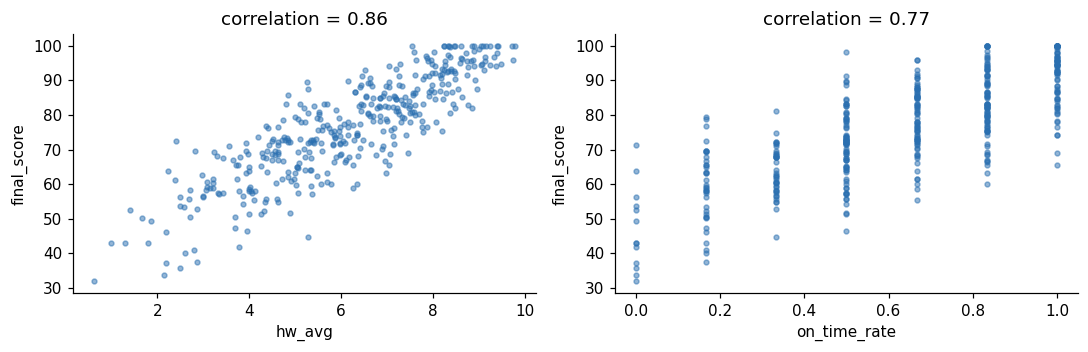

In [16]:
df["hw_avg"] = df[hw_score_cols].mean(axis=1)                    # .mean() skips blanks
df["on_time_rate"] = (df[hw_status_cols] == "on time").mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for ax, col in zip(axes, ["hw_avg", "on_time_rate"]):
    ax.scatter(df[col], df["final_score"], s=10, alpha=0.5, color="#2a6fb0")
    ax.set_xlabel(col); ax.set_ylabel("final_score")
    ax.set_title(f"correlation = {df[col].corr(df['final_score']):.2f}")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## Step 5 - Encode categories

### Patch 6 - Encode text categories
**Symptom:** `exercises` (`yes`/`no`) and `section` (`A`/`B`/`C`) are text, so Step 6 silently drops them. A model only understands numbers. *Requires Patch 2.*

**Predict before you paste:** will the scoreboard's R² go **up**, **down**, or **stay the same**? Write your guess here (double-click this cell): up

**Fix - copy this into the empty cell below, then Restart & Run All:**
```python
assert set(df["exercises"].dropna().unique()) <= {"yes", "no"}, "Apply Patch 2 first!"

df["exercises"] = df["exercises"].map({"yes": 1, "no": 0})                   # binary encoding
df = pd.get_dummies(df, columns=["section"], drop_first=True, dtype=int)   # one-hot encoding
print(df.filter(["exercises", "section_B", "section_C"]).head())
PATCHES.add(6)
```

In [17]:
assert set(df["exercises"].dropna().unique()) <= {"yes", "no"}, "Apply Patch 2 first!"

df["exercises"] = df["exercises"].map({"yes": 1, "no": 0})                   # binary encoding
df = pd.get_dummies(df, columns=["section"], drop_first=True, dtype=int)   # one-hot encoding
print(df.filter(["exercises", "section_B", "section_C"]).head())
PATCHES.add(6)

   exercises  section_B  section_C
0        1.0          1          0
1        NaN          0          1
2        1.0          0          0
3        1.0          1          0
4        1.0          0          0


> ### Checkpoint P6
> Patch 6 uses one-hot encoding for `section`. Why not just replace A, B, C with 1, 2, 3?
>
> **A)** The model would treat sections as ordered and evenly spaced (C is 'more' than A, B is halfway) - an order that does not exist  
> **B)** Numbers 1, 2, 3 make training slower  
> **C)** scikit-learn refuses numbers above 1  
> **D)** `get_dummies` is shorter to type  


In [18]:
check("P6", 'A')   # <- replace ? with your answer

[P6] Correct!
  Why: A single number column tells a linear model that sections are ordered and evenly spaced (B is halfway between A and C, C is 'more' than A). Sections have no order, so one-hot encoding gives each its own 0/1 column.


## Step 6 - Choose the features

In [19]:
df["passed"] = (df["final_score"] >= 60).astype(int)     # target for logistic regression (discrete)

FEATURES = [c for c in df.select_dtypes("number").columns if c not in ("final_score", "passed")]
print(f"Features used ({len(FEATURES)}):", FEATURES)

Features used (14): ['hw1_score', 'hw2_score', 'hw3_score', 'hw4_score', 'hw5_score', 'hw6_score', 'midterm_attendance', 'final_attendance', 'exercises', 'seat_row', 'hw_avg', 'on_time_rate', 'section_B', 'section_C']


How strongly does each candidate move with the final score? (`letter_grade` is added to the chart only to make a point.)

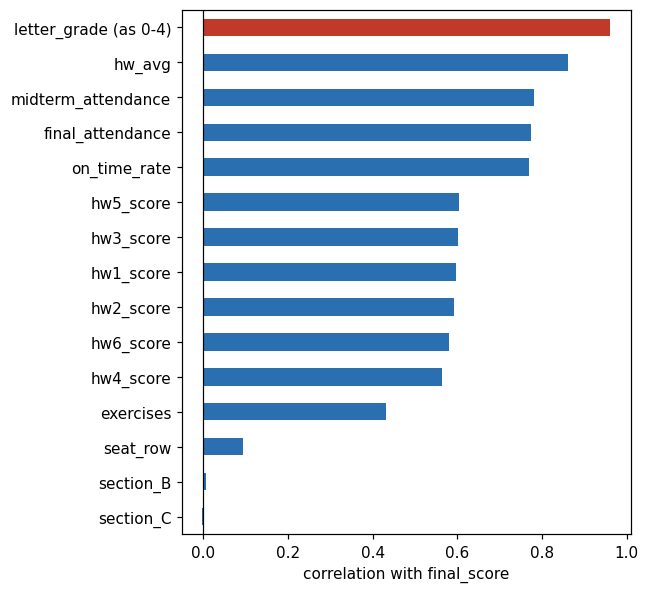

In [20]:
corr = df[FEATURES].corrwith(df["final_score"])
corr["letter_grade (as 0-4)"] = df["letter_grade"].map({"F": 0, "D": 1, "C": 2, "B": 3, "A": 4}).corr(df["final_score"])
corr = corr.sort_values()
ax = corr.plot.barh(figsize=(6, 0.3 * len(corr) + 1),
                    color=["#c0392b" if "letter" in c else "#2a6fb0" for c in corr.index])
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("correlation with final_score")
plt.tight_layout(); plt.show()

### Patch 7 - Select good features
What did this patch do here??
**Predict before you paste:** will the scoreboard's R² go **up**, **down**, or **stay the same**? Write your guess here (double-click this cell): up

**Fix - copy this into the empty cell below, then Restart & Run All:**
```python
# Keep only features that make sense: no IDs, no noise, no copies of hw_avg
GOOD = ["hw_avg", "on_time_rate", "midterm_attendance", "final_attendance",
        "exercises", "section_B", "section_C"]
FEATURES = [c for c in GOOD if c in FEATURES]
print("Features after selection:", FEATURES)
PATCHES.add(7)
```

In [21]:
GOOD = ["hw_avg", "on_time_rate", "midterm_attendance", "final_attendance",
        "exercises", "section_B", "section_C"]
FEATURES = [c for c in GOOD if c in FEATURES]
print("Features after selection:", FEATURES)
PATCHES.add(7)

Features after selection: ['hw_avg', 'on_time_rate', 'midterm_attendance', 'final_attendance', 'exercises', 'section_B', 'section_C']


> ### Checkpoint P7
> `letter_grade` has the highest correlation with `final_score` (red bar). Should we add it as a feature?
>
> **A)** Yes - it is clearly the best feature  
> **B)** No - it is computed from the final score, so it does not exist yet when we want to predict (target leakage)  
> **C)** Yes, but only after scaling it  
> **D)** Only for logistic regression  


In [22]:
check("P7", 'B')   # <- replace ? with your answer

[P7] Correct!
  Why: letter_grade is computed FROM final_score, so it is not available when we want to predict. Using it is target leakage: great test score, useless model.


## Step 7 - Train / test split
20% of students are held back as a **test set** that the models never see while learning. This is VERY IMPORTANT for any model training. REVIEW what is ML and think about why?

In [23]:
train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["passed"])
X_train, X_test = train[FEATURES].copy(), test[FEATURES].copy()
y_train_score, y_test_score = train["final_score"], test["final_score"]
y_train_pass, y_test_pass = train["passed"], test["passed"]
print("train:", X_train.shape, " test:", X_test.shape)
print("Blank cells left in X_train:", int(X_train.isna().sum().sum()))



train: (320, 7)  test: (80, 7)
Blank cells left in X_train: 59


## Step 8 - Fill the remaining blanks

In [24]:
fill_values = None   # Patch 8 will set this

### Patch 8 - Fill blanks with the TRAIN median

**Predict before you paste:** will the scoreboard's R² go **up**, **down**, or **stay the same**? Write your guess here (double-click this cell): stay the same

**Fix - copy this into the empty cell below, then Restart & Run All:**
```python
fill_values = X_train.median()            # learned from TRAIN students only
X_train = X_train.fillna(fill_values)
X_test = X_test.fillna(fill_values)       # the same numbers are used for test
print(fill_values.round(2).to_dict())
PATCHES.add(8)
```

In [25]:
fill_values = X_train.median()            # learned from TRAIN students only
X_train = X_train.fillna(fill_values)
X_test = X_test.fillna(fill_values)       # the same numbers are used for test
print(fill_values.round(2).to_dict())
PATCHES.add(8)

{'hw_avg': 6.35, 'on_time_rate': 0.67, 'midterm_attendance': 0.8, 'final_attendance': 0.71, 'exercises': 1.0, 'section_B': 0.0, 'section_C': 0.0}


In [26]:
X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

> ### Checkpoint P8
> Patch 8 computes the median from `X_train` only and applies it to both train and test. Why not compute it from all 400 students?
>
> **A)** It is faster  
> **B)** The test set stands for future students; using their values while preparing the training data leaks information and makes the test score too optimistic  
> **C)** The median of the test set cannot be computed  
> **D)** No reason - both are fine  


In [27]:
check("P8", 'B')   # <- replace ? with your answer

[P8] Correct!
  Why: The test set plays future students. Any number computed with their data (median, mean, scaler) lets information from the 'future' into training and makes the test score too optimistic. Fit on train, apply to both.


## Step 9 - Prepare the model inputs

In [28]:
print(X_train.describe().loc[["min", "max", "mean", "std"]].round(2))

scaler = None
X_train_model, X_test_model = X_train, X_test        

      hw_avg  on_time_rate  midterm_attendance  final_attendance  exercises  \
min     0.62          0.00                0.47              0.21       0.00   
max     9.78          1.00                1.00              1.00       1.00   
mean    6.15          0.64                0.80              0.72       0.63   
std     1.95          0.28                0.12              0.18       0.48   

      section_B  section_C  
min        0.00       0.00  
max        1.00       1.00  
mean       0.33       0.36  
std        0.47       0.48  


### Patch 9 - Scale the features
**Symptom:** `hw_avg` goes from 0 to 10 but attendance goes from 0 to 1 (see the table above). features on very different scales make those steps inefficient.

**Predict before you paste:** will the scoreboard's R² go **up**, **down**, or **stay the same**? Write your guess here (double-click this cell): ______

**Fix - copy this into the empty cell below, then Restart & Run All:**
```python
scaler = StandardScaler().fit(X_train)     # learn mean and std from TRAIN only
X_train_model = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)
X_test_model = pd.DataFrame(scaler.transform(X_test), columns=FEATURES, index=X_test.index)
print(X_train_model.describe().loc[["mean", "std"]].round(2))
PATCHES.add(9)
```

In [29]:
scaler = StandardScaler().fit(X_train)     # learn mean and std from TRAIN only
X_train_model = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)
X_test_model = pd.DataFrame(scaler.transform(X_test), columns=FEATURES, index=X_test.index)
print(X_train_model.describe().loc[["mean", "std"]].round(2))
PATCHES.add(9)

      hw_avg  on_time_rate  midterm_attendance  final_attendance  exercises  \
mean     0.0          -0.0                 0.0              -0.0       -0.0   
std      1.0           1.0                 1.0               1.0        1.0   

      section_B  section_C  
mean        0.0        0.0  
std         1.0        1.0  


## Step 10 - Scoreboard
Trains both models on the current pipeline and logs the result. **Re-run after every patch** (Restart & Run All).

To start the scoreboard over, set `RESET_SCOREBOARD = True` once.

In [30]:
RESET_SCOREBOARD = True

lin = LinearRegression().fit(X_train_model, y_train_score)
pred_score = lin.predict(X_test_model)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    logit = LogisticRegression().fit(X_train_model, y_train_pass)
p_pass = logit.predict_proba(X_test_model)[:, 1]
if any("converge" in str(w.message) for w in caught):
    print("⚠️  Logistic regression's optimizer stopped before it finished (ConvergenceWarning).")

fails = (y_test_pass == 0).values
label = "no patches" if not PATCHES else "patches " + ",".join(map(str, sorted(PATCHES)))
row = {"run": label, "students": len(df), "features": len(FEATURES),
       "R2": r2_score(y_test_score, pred_score), "MAE": mean_absolute_error(y_test_score, pred_score),
       "accuracy": accuracy_score(y_test_pass, p_pass >= 0.5),
       "fails_found": f"{((p_pass < 0.5) & fails).sum()} of {fails.sum()}",
       "AUC": roc_auc_score(y_test_pass, p_pass)}

log_file = OUT / "scoreboard.csv"
board = pd.read_csv(log_file) if log_file.exists() and not RESET_SCOREBOARD else pd.DataFrame()
if len(board):
    board = board[board["run"] != label]
board = pd.concat([board, pd.DataFrame([row])], ignore_index=True)
board.to_csv(log_file, index=False)

print(f"This run: {label}   ({len(PATCHES)} of 9 patches)\n")
board.round(3)

This run: patches 1,2,3,4,5,6,7,8,9   (9 of 9 patches)



,run,students,features,R2,MAE,accuracy,fails_found,AUC
0,"patches 1,2,3,4,5,6,7,8,9",400,7,0.828,4.777,0.862,7 of 12,0.941


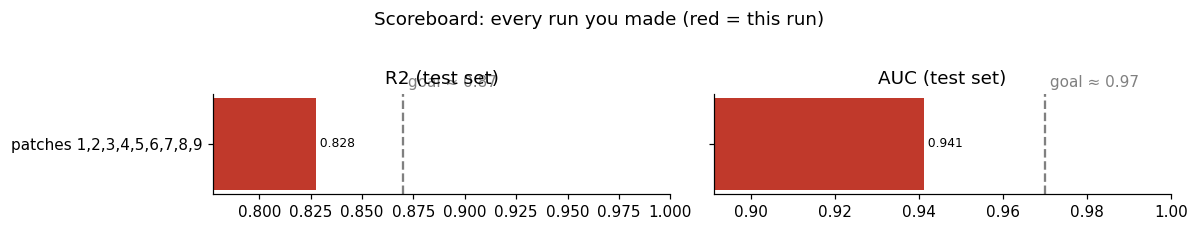

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 0.45 * len(board) + 1.6), sharey=True)
for ax, metric, goal in [(axes[0], "R2", 0.87), (axes[1], "AUC", 0.97)]:
    colors = ["#c0392b" if r == label else "#2a6fb0" for r in board["run"]]
    ax.barh(board["run"], board[metric], color=colors)
    ax.axvline(goal, ls="--", color="gray"); ax.text(goal, -0.6, f" goal ≈ {goal}", color="gray", va="top")
    lo = max(0, board[metric].min() - 0.05)
    ax.set_xlim(lo, 1.0); ax.set_title(f"{metric} (test set)")
    for y, v in enumerate(board[metric]):
        ax.text(v, y, f" {v:.3f}", va="center", fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].invert_yaxis()
plt.suptitle("Scoreboard: every run you made (red = this run)", y=1.0)
plt.tight_layout(); plt.show()

> ### Checkpoint P9
> After Patch 9 (scaling), the **linear regression R² did not change at all**, while logistic regression's AUC did. Why didn't linear regression change?
>
> **A)** The scaler did not run  
> **B)** Dividing a feature by a number just multiplies its coefficient by that number; least squares reaches exactly the same predictions  
> **C)** Linear regression ignores the features  
> **D)** R² is rounded to 3 digits  


In [32]:
check("P9", 'B')   # <- replace ? with your answer

[P9] Correct!
  Why: Scaling a feature by a constant just scales its coefficient the other way; least squares reaches exactly the same predictions, so R2 does not change. Scaling matters for gradient descent, regularization and comparing coefficients - see notebook 03.


## Step 11 - Save for notebooks 02 and 03

In [33]:
def with_ids(part, X):
    return pd.concat([part[["student_id"]], X, part[["final_score", "passed"]]], axis=1)

with_ids(train, X_train).to_csv(DATA / "train_processed.csv", index=False)      # unscaled
with_ids(test, X_test).to_csv(DATA / "test_processed.csv", index=False)
with_ids(train, X_train_model).to_csv(DATA / "train_scaled.csv", index=False)   # scaled (if Patch 9)
with_ids(test, X_test_model).to_csv(DATA / "test_scaled.csv", index=False)
joblib.dump({"features": FEATURES, "scaler": scaler, "patches": sorted(PATCHES),
             "fill_values": None if fill_values is None else fill_values.to_dict()},
            DATA / "preprocessing.joblib")

missing = sorted(set(range(1, 10)) - PATCHES)
print("Saved. Patches applied:", sorted(PATCHES))
if missing:
    print("⚠️  Still missing patches:", missing, "- notebooks 02 and 03 will run, but with a weaker pipeline.")

Saved. Patches applied: [1, 2, 3, 4, 5, 6, 7, 8, 9]


## Checkpoint summary

In [34]:
summary("P")

Correct: 9 / 9   P1 P2 P3 P4 P5 P6 P7 P8 P9


## Wrap-up: what each patch fixed
Review and summary what did the patches do and what are the effects on model traiing.

## Your turn (discussion)
1. Which patch improved the scoreboard the most? Which one did you predict wrong, and why?
2. Turn off Patch 7 only (comment out its lines) and add `"letter_grade"` - encoded as numbers - to the features. What R² do you get? and why??
3. Patch 5 sets `120%` attendance to blank. Someone suggests changing it to `100%` instead. Give one argument for each choice.

**Next:** `02_linear_regression.ipynb`

In [35]:
# )1 
# The path that improved the scoreboad the most is patch 6 and patch 7. 
# Honestly, I was not sure wheather R^2 would go up, down, or stay the same for the different paths, so my 
# predections were completely off across the board. However, I was suprised that patch 6 and 7 would make the biggest R^2 jumps
# amoung the other pathchs and I was not expecting that.  

In [36]:
# 2) 
# The R^2 value is 0.925 becuase you are giving the model the letter_grade which is the final students grade so it can accuratly calculate so that is why R^2 shoots up

In [37]:
#3) 
# Setting the attendance to 120% is impossible percentage but then setting to a blank value makes it easier for the machine to clean it up
# On the other hand, setting it to 120% could mean the student attended all of the class and got extra credit but changing it to 100% seems more of a better plan as it makes sense that the student attend 100% of the class which makes sense